In [1]:
# Load and profile a dataset (shape, dtypes, null counts, duplicates)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("eda_sales_data.csv")

In [3]:
df.head()

,order_id,region,product,category,quantity,price,sales
0,1,North,Laptop,Electronics,2.0,800.0,1600.0
1,2,South,Mouse,Accessories,5.0,20.0,100.0
2,3,East,Keyboard,Accessories,3.0,50.0,150.0
3,4,West,Monitor,Electronics,2.0,300.0,600.0
4,5,North,Laptop,Electronics,4.0,800.0,3200.0


In [4]:
df.shape

(21, 7)

In [5]:
df.dtypes

order_id      int64
region       object
product      object
category     object
quantity    float64
price       float64
sales       float64
dtype: object

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  21 non-null     int64  
 1   region    21 non-null     object 
 2   product   21 non-null     object 
 3   category  21 non-null     object 
 4   quantity  20 non-null     float64
 5   price     20 non-null     float64
 6   sales     20 non-null     float64
dtypes: float64(3), int64(1), object(3)
memory usage: 1.3+ KB


In [7]:
df.isnull().sum()

order_id    0
region      0
product     0
category    0
quantity    1
price       1
sales       1
dtype: int64

In [8]:
df.duplicated().sum()

1

In [9]:
# Visualise distributions for all numeric columns

numeric_columns = df.select_dtypes(include="number").columns
numeric_columns

Index(['order_id', 'quantity', 'price', 'sales'], dtype='object')

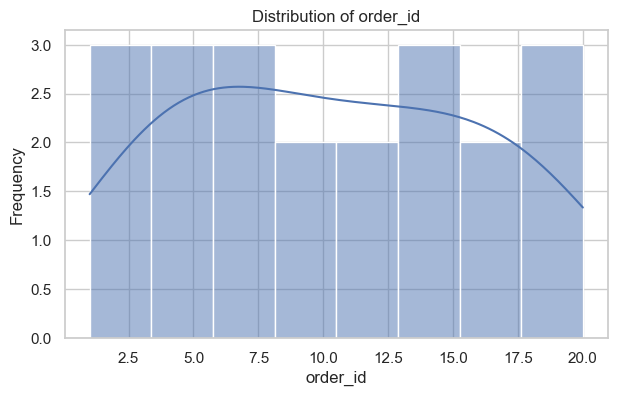

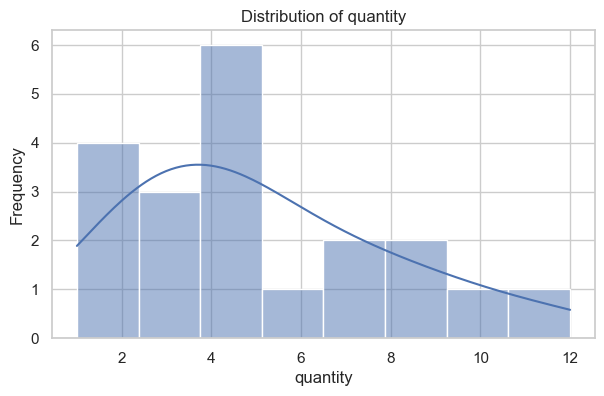

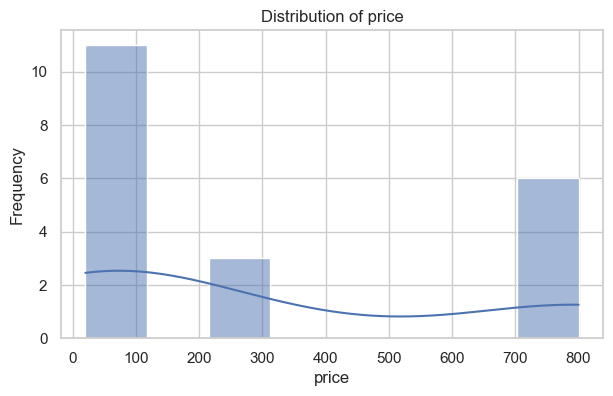

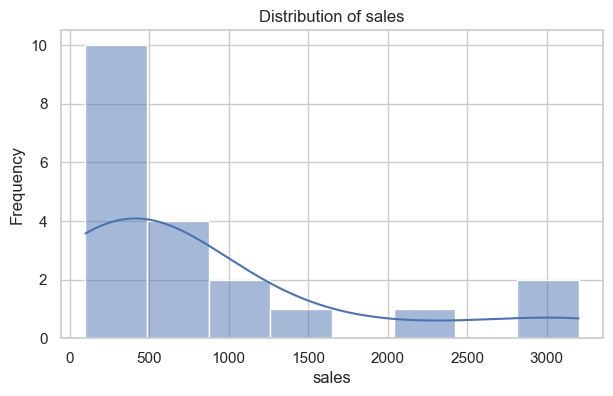

In [10]:
for column in numeric_columns:
    plt.figure(figsize=(7, 4))
    
    sns.histplot(df[column], bins=8, kde=True)
    
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    
    plt.show()

In [11]:
numeric_columns = df.select_dtypes(include="number").columns
numeric_columns

Index(['order_id', 'quantity', 'price', 'sales'], dtype='object')

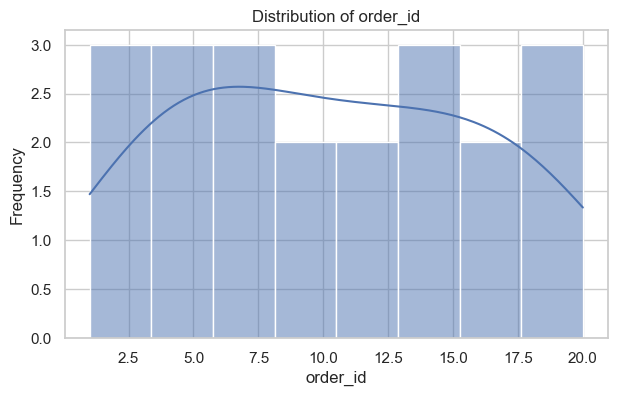

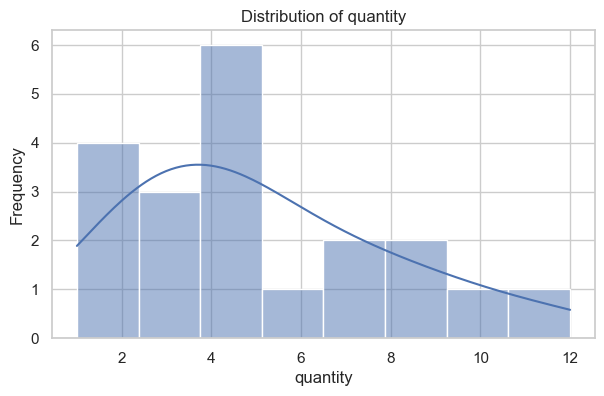

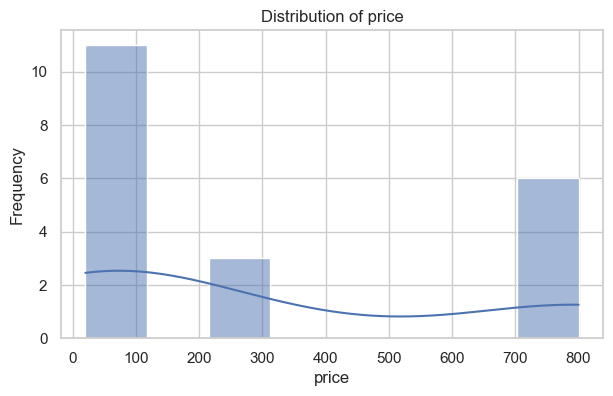

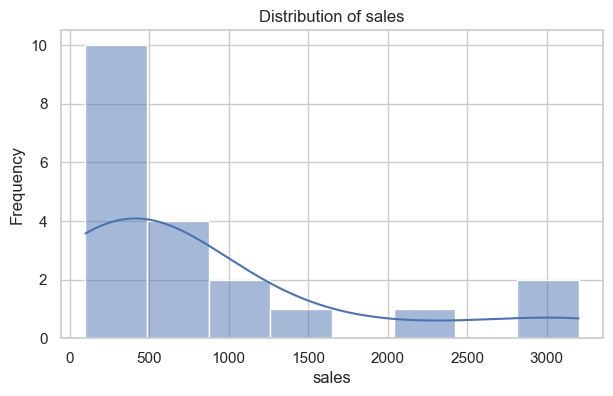

In [12]:
for column in numeric_columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[column], bins=8, kde=True)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()

In [13]:
# Identify correlations using a heatmap

correlation = df[numeric_columns].corr()

correlation

,order_id,quantity,price,sales
order_id,1.000000,0.363189,-0.082909,-0.192743
quantity,0.363189,1.000000,-0.606393,-0.382618
price,-0.082909,-0.606393,1.000000,0.859697
sales,-0.192743,-0.382618,0.859697,1.000000


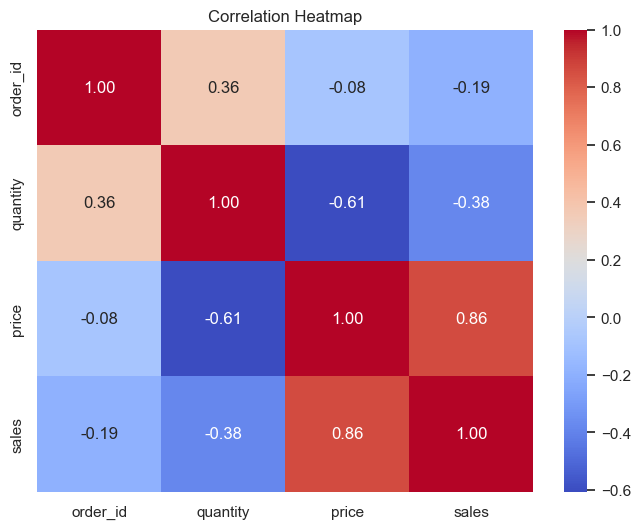

In [14]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

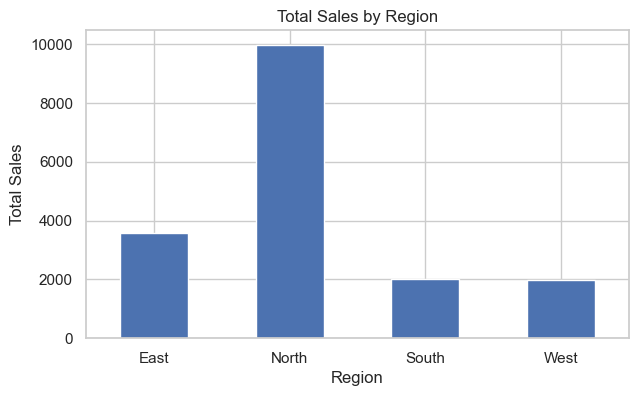

In [15]:
# Document 5 business insights with supporting charts

# 1. Sales by Region
region_sales = df.groupby("region")["sales"].sum()

plt.figure(figsize=(7, 4))
region_sales.plot(kind="bar")
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()

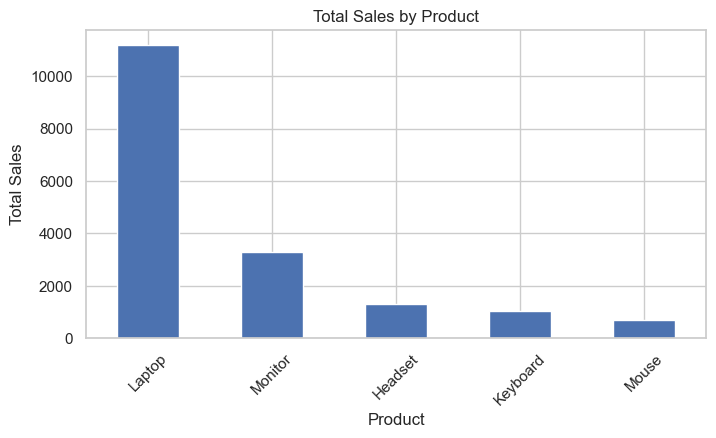

In [16]:
# 2. Sales by Product
product_sales = df.groupby("product")["sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
product_sales.plot(kind="bar")
plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

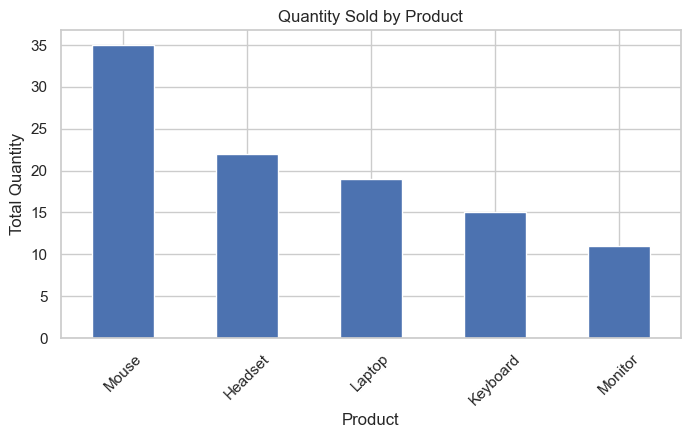

In [17]:
# 3. Quantity Sold by Product
product_quantity = df.groupby("product")["quantity"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
product_quantity.plot(kind="bar")
plt.title("Quantity Sold by Product")
plt.xlabel("Product")
plt.ylabel("Total Quantity")
plt.xticks(rotation=45)
plt.show()

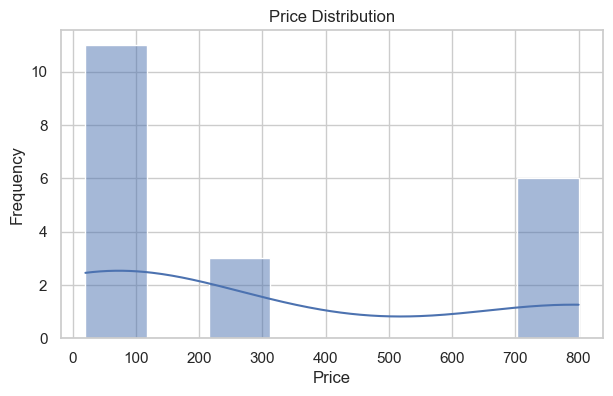

In [18]:
# 4. Price Distribution
plt.figure(figsize=(7, 4))
sns.histplot(df["price"], bins=8, kde=True)
plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

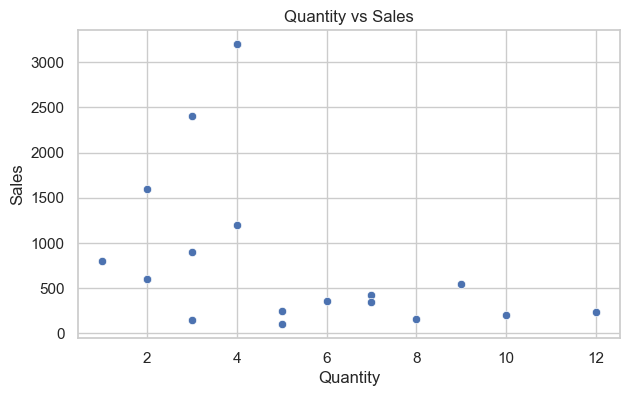

In [19]:
# 5. Quantity vs Sales
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="quantity", y="sales")
plt.title("Quantity vs Sales")
plt.xlabel("Quantity")
plt.ylabel("Sales")
plt.show()

In [20]:
# Create a summary statistics table

summary_stats = df.describe()

summary_stats

,order_id,quantity,price,sales
count,21.000000,20.000000,20.000000,20.000000
mean,10.238095,5.100000,308.000000,878.500000
std,5.889862,2.954034,342.983811,973.411121
min,1.000000,1.000000,20.000000,100.000000
25%,5.000000,3.000000,50.000000,247.500000
50%,10.000000,4.500000,60.000000,480.000000
75%,15.000000,7.000000,800.000000,975.000000
max,20.000000,12.000000,800.000000,3200.000000


In [21]:
summary_stats = df.describe().round(2)

summary_stats

,order_id,quantity,price,sales
count,21.00,20.00,20.00,20.00
mean,10.24,5.10,308.00,878.50
std,5.89,2.95,342.98,973.41
min,1.00,1.00,20.00,100.00
25%,5.00,3.00,50.00,247.50
50%,10.00,4.50,60.00,480.00
75%,15.00,7.00,800.00,975.00
max,20.00,12.00,800.00,3200.00


In [22]:
categorical_summary = df.describe(include="object")

categorical_summary

,region,product,category
count,21,21,21
unique,4,5,2
top,North,Laptop,Accessories
freq,6,6,11


In [23]:
summary_stats.to_csv("summary_statistics.csv")